In [4]:
import sqlite3
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report

RAW_PATH = "/content/credit_risk_dataset.csv"
DB_PATH = "/content/credit_risk.db"

**Extract** the data from the CSV File

In [5]:
def extract(path):
  df = pd.read_csv(path)
  print(f'Extracted {len(df):,} rows')
  return df
raw = extract(RAW_PATH)
raw.head()

Extracted 32,581 rows


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4



**Transform**

Delete Duplicates
Keep Rows that are not bad
collects the rejected rows



In [7]:
def transform(df):
  df = df.drop_duplicates()
  bad = (df.person_age > 100) | (df.person_emp_length > 60)
  return df[~bad].copy(), df[bad].copy()
clean, rejected = transform(raw)
print(f'Clean : {len(clean):,} | Rejected: {len(rejected)}')

Clean : 32,409 | Rejected: 7


**Load**

Load the dataframe into SQL lite database as table

creates two tables clean and rejected

In [8]:
def load(clean, rejected, db):
  con = sqlite3.connect(db)
  clean.to_sql('clean_loans', con, if_exists='replace', index=False)
  rejected.to_sql('rejected_loans', con, if_exists='replace', index=False)
  con.close()
load(clean, rejected, DB_PATH)
pd.read_sql("SELECT COUNT(*) AS n FROM rejected_loans", sqlite3.connect(DB_PATH))

,n
0,7


Connect to SQL database

Have loan grade, total number of loans, and percentage that has defaulted

In [9]:
con = sqlite3.connect(DB_PATH)
pd.read_sql("""
    SELECT loan_grade, COUNT(*) AS loans,
           ROUND(AVG(loan_status)*100,1) AS default_pct
    FROM clean_loans GROUP BY loan_grade ORDER BY loan_grade
""", con)

,loan_grade,loans,default_pct
0,A,10702,10.0
1,B,10384,16.3
2,C,6436,20.8
3,D,3619,59.0
4,E,963,64.5
5,F,241,70.5
6,G,64,98.4


Same as before but with person_home_ownership


In [10]:
con = sqlite3.connect(DB_PATH)
pd.read_sql("""
    SELECT person_home_ownership, COUNT(*) AS loans,
           ROUND(AVG(loan_status)*100,1) AS default_pct
    FROM clean_loans GROUP BY person_home_ownership ORDER BY person_home_ownership
""", con)

,person_home_ownership,loans,default_pct
0,MORTGAGE,13366,12.6
1,OTHER,106,31.1
2,OWN,2563,7.5
3,RENT,16374,31.6


Same as before but with loan_intent



In [11]:
con = sqlite3.connect(DB_PATH)
pd.read_sql("""
    SELECT loan_intent, COUNT(*) AS loans,
           ROUND(AVG(loan_status)*100,1) AS default_pct
    FROM clean_loans GROUP BY loan_intent ORDER BY loan_intent
""", con)

,loan_intent,loans,default_pct
0,DEBTCONSOLIDATION,5189,28.7
1,EDUCATION,6409,17.3
2,HOMEIMPROVEMENT,3594,26.2
3,MEDICAL,6042,26.8
4,PERSONAL,5496,19.9
5,VENTURE,5679,14.9


Training the random forest

Seperating Numeric and categorical data

Using column transformer one Hot Encoder to transform categorical data

Using Simple imputer as well.

Puts data into RandomForest Classifier

Fitting model

In [12]:
df = pd.read_sql("Select * FROM clean_loans", sqlite3.connect(DB_PATH))
X, y = df.drop(columns=['loan_status']), df['loan_status']
num = X.select_dtypes(include='number').columns
cat = X.select_dtypes(exclude='number').columns

prep = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
    ('num', SimpleImputer(strategy='median'), num),
])

model = Pipeline([
    ('prep', prep),
    ('rf', RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5,
                       class_weight="balanced_subsample",
                       random_state=42, n_jobs=-1)),
])

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
model.fit(x_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object')),
                                                 ('num',
                                                  SimpleImputer(strategy='median'),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object'))])),
                ('rf',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        max_depth=12, min_samples_leaf=5,
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

Found that the model correctly chose the defaulter about 94% of the time but only caught about 73% of the loans that defaulted. Since it is a higher risk to keep people that ddefault I want to lower the threshold since the cost of catching people who defaulted is higher

In [13]:
prob = model.predict_proba(x_test)[:,1]
print("Test AUC: ", roc_auc_score(y_test, prob))
print("Train AUC: ", roc_auc_score(y_train, model.predict_proba(x_train)[:,1]))
print(classification_report(y_test, model.predict(x_test)))

Test AUC:  0.9317240032798793
Train AUC:  0.9616345480853222
              precision    recall  f1-score   support

           0       0.93      0.96      0.95      5064
           1       0.84      0.76      0.80      1418

    accuracy                           0.92      6482
   macro avg       0.89      0.86      0.87      6482
weighted avg       0.91      0.92      0.91      6482



Used help from claud to see how I could print out the specific threshold values I wanted to choose. I saw that 0.35 seemed to be the best. Even though its accuracy went down, we were less likely to choose a loan deafulter which is cost effective. Went up from 73 to 84%

In [14]:
from sklearn.metrics import precision_score, recall_score

rows = []
for t in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55]:
    p = (prob >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": round(precision_score(y_test, p), 3),
                 "recall": round(recall_score(y_test, p), 3),
                 "flagged": int(p.sum())})
pd.DataFrame(rows)

,threshold,precision,recall,flagged
0,0.20,0.371,0.950,3629
1,0.25,0.451,0.908,2853
2,0.30,0.547,0.873,2264
3,0.35,0.630,0.841,1892
4,0.40,0.711,0.805,1605
5,0.45,0.782,0.778,1411
6,0.50,0.843,0.755,1271
7,0.55,0.902,0.742,1166


Used the threshold to calculate a new precision recall curve and got a value that I was happy about which accounted for cost as well.

Precision: Of flagged loans, the share that truly default (0.63).
Recall: Of all defaults, the share you caught (0.84).

In [15]:
from sklearn.metrics import confusion_matrix

THRESHOLD = 0.35
preds = (prob >= THRESHOLD).astype(int)
print(classification_report(y_test, preds))
print(confusion_matrix(y_test, preds))

              precision    recall  f1-score   support

           0       0.95      0.86      0.90      5064
           1       0.63      0.84      0.72      1418

    accuracy                           0.86      6482
   macro avg       0.79      0.85      0.81      6482
weighted avg       0.88      0.86      0.86      6482

[[4364  700]
 [ 226 1192]]


Showed me the important variables and predictors

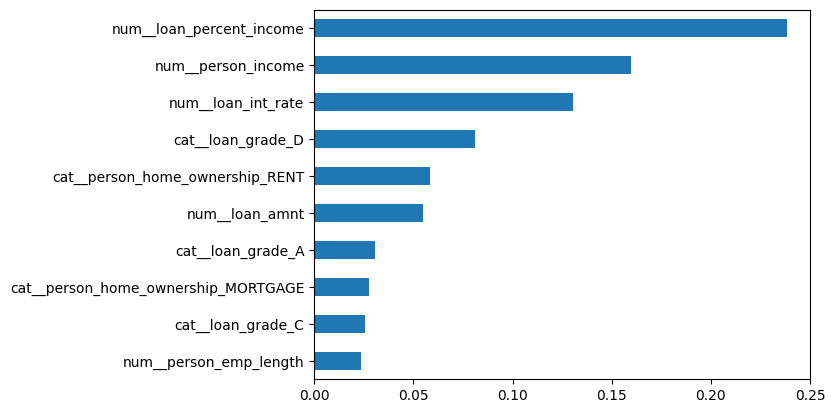

In [16]:
names = model.named_steps["prep"].get_feature_names_out()
imp = pd.Series(model.named_steps["rf"].feature_importances_, index=names)
imp.sort_values().tail(10).plot.barh();

I used logistic regression as well to check if it was more effective than Random Forest. I found that Random Forest ranks considerably better than logistic regression which makes me believe the data isnt linear

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import numpy as np
import matplotlib.pyplot as plt

prep_lr = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat),
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc', StandardScaler())]), num),
])

logit = Pipeline([
    ('prep', prep_lr),
    ('lr', LogisticRegression(max_iter=1000)),   # no class_weight, see note below
])
logit.fit(x_train, y_train)

p_lr = logit.predict_proba(x_test)[:, 1]
print("Logistic Regression Test AUC:", roc_auc_score(y_test, p_lr))
print("Random Forest Test AUC:      ", roc_auc_score(y_test, prob))

Logistic Regression Test AUC: 0.870176689015301
Random Forest Test AUC:       0.9317240032798793


Found that certain predictors show sign of more risk in defaulting while others show less of defaulting.

                                   coef  odds_ratio
cat__loan_grade_G                 4.396      81.151
cat__loan_grade_F                 2.842      17.146
cat__loan_grade_E                 2.549      12.799
cat__loan_grade_D                 2.317      10.148
cat__person_home_ownership_OWN   -1.709       0.181
num__loan_percent_income          1.437       4.210
cat__loan_intent_VENTURE         -1.088       0.337
cat__loan_intent_EDUCATION       -0.859       0.424
cat__person_home_ownership_RENT   0.836       2.308
num__loan_amnt                   -0.692       0.500
cat__loan_intent_PERSONAL        -0.645       0.525
cat__person_home_ownership_OTHER  0.483       1.622
cat__loan_grade_C                 0.279       1.321
num__loan_int_rate                0.260       1.298
cat__loan_intent_MEDICAL         -0.211       0.810


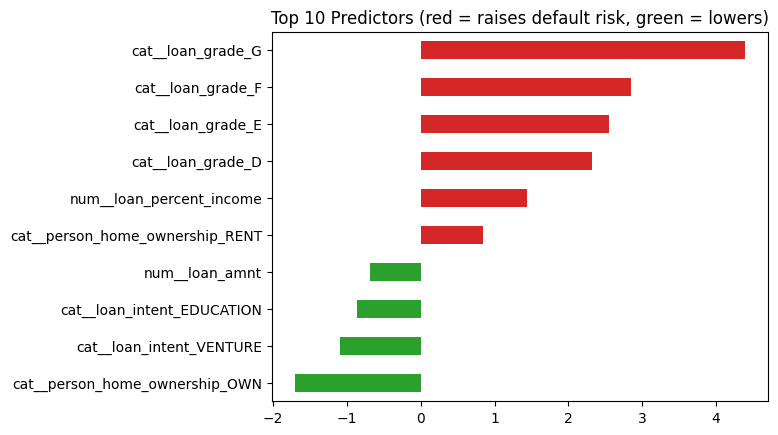

In [19]:
names = logit.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(logit.named_steps['lr'].coef_[0], index=names)

summary = pd.DataFrame({'coef': coefs, 'odds_ratio': np.exp(coefs)})
summary = summary.reindex(coefs.abs().sort_values(ascending=False).index)
print(summary.head(15).round(3))

top = summary.head(10).sort_values('coef')
top['coef'].plot.barh(color=['tab:green' if c < 0 else 'tab:red' for c in top['coef']])
plt.title("Top 10 Predictors (red = raises default risk, green = lowers)")
plt.show()

Goal:

Predict loan default (loan_status) from borrower and loan details. About 32,400 loans after cleaning, 22% default.

ETL:

Dropped duplicates, rejected impossible rows (age over 100, employment over 60 years), and loaded clean and rejected rows to SQLite. This shows you check data quality before modeling.

Stratified split:

 Keeps the 22% default rate the same in train and test, which matters because defaults are the minority class.**bold text**

What drives default

Loan grade: Strongest driver. Odds rise steadily from A to G.

Home ownership:

Owners have far lower odds than mortgage holders. Renters have higher.

Loan as % of income:

Strongest numeric driver. The raw data shows a cliff above about 30% of income (about 70% default).

Interest rate:

Risk accelerates above about 15%.

Assumption:

Approving a defaulter costs more than declining a good borrower.
Threshold 0.35 (instead of 0.50): Recall rose from 73% to 84%. Precision is 63%, so 37% of flags are good borrowers.

Confusion matrix:

1,192 defaults caught, 226 missed, 700 good borrowers declined.

Trade-off:

Roughly 4 extra good borrowers declined per extra default caught (approximate, from your rounded figures). This only pays off if a default costs more than about 4 times a declined good loan.

Weakness:

The threshold was chosen on the test set, so the 84% is slightly optimistic. Better to choose it on a validation set.